In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torch import nn
import copy

import torch.nn as nn
import torch.optim as optim
import torch

from sklearn.preprocessing import StandardScaler
import joblib

import json
import wandb

In [3]:
data_comfort = pd.read_csv("building_database_training_final.csv")

In [ ]:
wandb.init(
    project="comfort_surr_uns",  # name of your W&B project
    name="FinalOverheat_Underheat_H3_S128_LR0.001",
    config={
        "learning_rate": 0.001,
        "batch_size": 64,
        "epochs": 600,
        "hidden_size": 128,
        "hidden_layers": 3,
        "model_type": "MLP"
    }
)

wandb.run.notes =  """ 
one_hot_columns = ['heat_system_type_gas_boiler',
                'heat_system_type_heat_pump', 'heat_system_type_district_heating', 
                'heat_system_type_no_heating', 'cool_system_type_no_cooling',
                'cool_system_type_dx_airco', 'archetype_mapped_1', 'archetype_mapped_2', 'archetype_mapped_3',
                'archetype_mapped_6', 'archetype_mapped_7']
numeric_columns = ['idf_num_floors', 'pp_ht_floor', 'pp_orientation',
                'idf_total_floor_area', 'idf_exposed_wall_area', 'idf_compact_ratio', 'idf_adiab_wall_area',
                'r_wall_ins', 'r_roof_ins', 'r_floor_ins', 'u_window', 'shgc', 'inf_rate_q4', 'boiler_eff', 'hp_cop', 'dx_cop',
                'idf_ground_floor_area', 'idf_window_area', 'lighting', 'electrical_equipment', 'people']

label_column = ['int_under_cum_m2', 'int_over_cum_m2']
                """

wandb: Currently logged in as: a-m-koniari (a-m-koniari-tu-delft) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Exception in thread IntMsgThr:
Traceback (most recent call last):
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\threading.py", line 980, in _bootstrap_inner
    self.run()
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\site-packages\ipykernel\ipkernel.py", line 766, in run_closure
    _threading_Thread_run(self)
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\threading.py", line 917, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\site-packages\wandb\sdk\wandb_run.py", line 335, in check_internal_messages
    self._loop_check_status(
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\site-packages\wandb\sdk\wandb_run.py", line 238, in _loop_check_status
    local_handle = request()
  File "c:\Users\amkoniari\Anaconda3\envs\dsaie\lib\site-packages\wandb\sdk\interface\interface.py", line 1014, in deliver_internal_messages
    return self._deliver_internal_messages(internal_message)
  File "c:\Users\amkoniari\Anacond

In [16]:
# Define input features
one_hot_columns = ['heat_system_type_gas_boiler',
                'heat_system_type_heat_pump', 'heat_system_type_district_heating', 
                'heat_system_type_no_heating', 'cool_system_type_no_cooling',
                'cool_system_type_dx_airco', 'archetype_mapped_1', 'archetype_mapped_2', 'archetype_mapped_3',
                'archetype_mapped_6', 'archetype_mapped_7']
numeric_columns = ['idf_num_floors', 'pp_ht_floor', 'pp_orientation',
                'idf_total_floor_area', 'idf_exposed_wall_area', 'idf_compact_ratio', 'idf_adiab_wall_area',
                'r_wall_ins', 'r_roof_ins', 'r_floor_ins', 'u_window', 'shgc', 'inf_rate_q4', 'boiler_eff', 'hp_cop', 'dx_cop',
                'idf_ground_floor_area', 'idf_window_area', 'lighting', 'electrical_equipment', 'people']

label_column = ['int_under_cum_m2', 'int_over_cum_m2']

In [25]:
class NeuralNet_3_Ln_2DBottleneck(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, hidden_size3, output_size):
        super(NeuralNet_3_Ln_2DBottleneck, self).__init__()

        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.ln1 = nn.LayerNorm(hidden_size1)
        self.activation1 = nn.ReLU()

        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.ln2 = nn.LayerNorm(hidden_size2)
        self.activation2 = nn.ReLU()

        self.fc3 = nn.Linear(hidden_size2, hidden_size3)
        self.ln3 = nn.LayerNorm(hidden_size3)
        self.activation3 = nn.ReLU()

        # 2D bottleneck
        self.embedding_2d = nn.Linear(hidden_size3, 2)
        self.activation4 = nn.ReLU()

        # Regression output now uses the 2D embedding
        self.output = nn.Linear(2, output_size)

    def forward(self, x, return_embedding=False):
        x = self.fc1(x)
        x = self.ln1(x)
        x = self.activation1(x)

        x = self.fc2(x)
        x = self.ln2(x)
        x = self.activation2(x)

        x = self.fc3(x)
        x = self.ln3(x)
        x = self.activation3(x)

        z = self.embedding_2d(x)   # shape: [batch_size, 2]
        x = self.activation4(z)
        y = self.output(x)         # shape: [batch_size, output_size]

        if return_embedding:
            return y, z

        return y

In [20]:
# Define a custom class for the BuildingDataset
class BuildingDataset(Dataset):
    def __init__(self, inputs, outputs):
        self.inputs = inputs
        self.outputs = outputs

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return self.inputs[idx], self.outputs[idx]

In [17]:
# Create input tensor
one_hot_features = data_comfort[one_hot_columns].values

input_scaler=StandardScaler()
numeric_features = data_comfort[numeric_columns].values
numeric_scaled = input_scaler.fit_transform(numeric_features)
input_tensor = torch.cat((torch.tensor(one_hot_features, dtype=torch.float32), torch.tensor(numeric_scaled, dtype=torch.float32)), dim=1)

In [21]:
# Log-transform overheating values & Create output tensor
target_df = data_comfort[label_column].copy()
target_df['int_over_cum_m2'] = np.log1p(target_df['int_over_cum_m2'].clip(lower=0))

output_scaler=StandardScaler()
output_scaled = output_scaler.fit_transform(target_df)
output_tensor = torch.tensor(output_scaled, dtype=torch.float32)

# Calculate xero means so that, when applying the Hadamard product, the values become zero in the scaled space
enforced_zero_means = (0-output_scaler.mean_)/output_scaler.scale_

In [22]:
seed=42
torch.manual_seed(seed)

#Split into training and test dataset
X_train_full, X_test, y_train_full, y_test = train_test_split(input_tensor, output_tensor, test_size=0.2, random_state=seed)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=seed) 

train_dataset = BuildingDataset(X_train, y_train)
val_dataset = BuildingDataset(X_val, y_val)
test_dataset = BuildingDataset(X_test, y_test)

X_train.shape, X_val.shape, X_test.shape

(torch.Size([105264, 32]), torch.Size([35088, 32]), torch.Size([35088, 32]))

In [ ]:
scaled_zero_targets = torch.tensor(enforced_zero_means, dtype=torch.float32)
mask_comfort_heat = torch.tensor([
    [0, 1],  # gas boiler
    [0, 1],  # heat pump
    [0, 1],  # district heating
    [1, 1]   # no heating
], dtype=torch.float32) # Make 0 when there is a heating system

mask_comfort_cool = torch.tensor([
    [1, 1],  # no cooling
    [1, 0],  # dx airco 
], dtype=torch.float32) # Make 0 when there is cooling system

In [ ]:
epochs = 600
batch_size = 64
learning_rate = 0.001

input_size=input_tensor.shape[1]
hidden_size1=128
hidden_size2=128
hidden_size3=128
output_size=output_tensor.shape[1]

model = NeuralNet_3_Ln_2DBottleneck(input_size, hidden_size1, hidden_size2, hidden_size3, output_size)
optimizer = optim.Adam(model.parameters(), learning_rate)
criterion = nn.MSELoss()

32 2


In [23]:
def apply_scaled_zero_mask(outputs, labels, final_mask, scaled_zero_targets):
    zero_targets = scaled_zero_targets.unsqueeze(0).to(outputs.device)
    outputs_masked = outputs * final_mask + zero_targets * (1.0 - final_mask)
    labels_masked = labels * final_mask + zero_targets * (1.0 - final_mask)
    return outputs_masked, labels_masked

def compute_metrics_once(output_scaler, all_labels, all_preds):
    all_preds_np = all_preds.detach().cpu().numpy()
    all_labels_np = all_labels.detach().cpu().numpy()

    mae_per_output = []
    mse_per_output = []
    mape_per_output = []
    mpe_per_output = []

    all_preds_denorm = output_scaler.inverse_transform(all_preds_np)
    all_labels_denorm = output_scaler.inverse_transform(all_labels_np)

    # Convert back to original units for the log-transformed overheating target
    over_idx = label_column.index('int_over_cum_m2')
    all_preds_denorm[:, over_idx] = np.expm1(all_preds_denorm[:, over_idx])
    all_labels_denorm[:, over_idx] = np.expm1(all_labels_denorm[:, over_idx])
    eps=0.1

    for i in range(all_preds_np.shape[1]):
        y_true = all_labels_denorm[:, i]
        y_pred = all_preds_denorm[:, i]

        valid = np.abs(y_true) > eps
        abs_errors = np.abs(y_pred[valid] - y_true[valid])
        abs_percentage_errors = np.abs((y_pred[valid] - y_true[valid]) / y_true[valid]) * 100
        percentage_errors = ((y_pred[valid] - y_true[valid]) / y_true[valid]) * 100
        mse_errors = ((y_pred[valid] - y_true[valid]) ** 2)

        mae = np.mean(abs_errors)
        mape = np.mean(abs_percentage_errors)
        mpe = np.mean(percentage_errors)
        mse = np.mean(mse_errors)

        mae_per_output.append(mae)
        mse_per_output.append(mse)
        mape_per_output.append(mape)
        mpe_per_output.append(mpe)

    return mae_per_output, mse_per_output, mape_per_output, mpe_per_output

In [ ]:
# Model training and validation
train_losses = []

train_loader = DataLoader(train_dataset, batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size, shuffle=False)

wandb.watch(model, log="all", log_freq=30)

heat_slice = slice(0, 4)
cool_slice = slice(4, 6)
input_feature_names = one_hot_columns + numeric_columns

best_mape_over= float("inf")
best_model_state_over = copy.deepcopy(model.state_dict())
best_epoch_over = -1

best_mape_under= float("inf")
best_model_state_under = copy.deepcopy(model.state_dict())
best_epoch_under = -1

for epoch in range(epochs):
    model.train()
    train_loss = 0.0

    for batch_features, batch_labels in train_loader:

        optimizer.zero_grad()
        batch_features = batch_features.detach().clone().requires_grad_(True)
        outputs = model(batch_features)

        heat_onehot = batch_features[:, heat_slice]
        cool_onehot = batch_features[:, cool_slice]

        heat_idx = heat_onehot.argmax(dim=1)
        cool_idx = cool_onehot.argmax(dim=1)

        heat_mask_batch = mask_comfort_heat[heat_idx]  
        cool_mask_batch = mask_comfort_cool[cool_idx]
        final_mask = heat_mask_batch * cool_mask_batch      

        outputs_masked, labels_masked = apply_scaled_zero_mask(
            outputs, batch_labels, final_mask, scaled_zero_targets
        )

        loss = criterion(outputs_masked, labels_masked)
        loss.backward()

        wandb.log({
            "grad_norm/fc1": model.fc1.weight.grad.norm().item(),
            "grad_norm/fc2": model.fc2.weight.grad.norm().item(),
            "grad_norm/fc3": model.fc3.weight.grad.norm().item(),
            "grad_norm/embedding_2d": model.embedding_2d.weight.grad.norm().item(),
            "grad_norm/output": model.output.weight.grad.norm().item(),
        })

        input_grad_mean_abs = batch_features.grad.detach().abs().mean(dim=0).cpu().numpy()

        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0.0
    val_preds_epoch = []
    val_labels_epoch = []

    with torch.no_grad():
        for batch_features, batch_labels in val_loader:
            outputs = model(batch_features)

            heat_onehot = batch_features[:, heat_slice]
            heat_idx = heat_onehot.argmax(dim=1)
            heat_mask_batch = mask_comfort_heat[heat_idx]

            cool_onehot = batch_features[:, cool_slice]
            cool_idx = cool_onehot.argmax(dim=1)
            cool_mask_batch = mask_comfort_cool[cool_idx]
            final_mask = heat_mask_batch * cool_mask_batch

            outputs_masked, labels_masked = apply_scaled_zero_mask(
                outputs, batch_labels, final_mask, scaled_zero_targets
            )

            loss = criterion(outputs_masked, labels_masked)
            val_loss += loss.item()
            val_preds_epoch.append(outputs_masked.detach())
            val_labels_epoch.append(labels_masked.detach())

    val_loss /= len(val_loader)

    all_val_preds = torch.cat(val_preds_epoch, dim=0)
    all_val_labels = torch.cat(val_labels_epoch, dim=0)
    mae_val, mse_val, mape_val, mpe_val = compute_metrics_once(output_scaler, all_val_labels, all_val_preds)

    if  mape_val[0] < best_mape_under:
        best_mape_under = mape_val[0]
        best_model_state_under = copy.deepcopy(model.state_dict())
        best_epoch_under = epoch + 1

    if  mape_val[1] < best_mape_over:
        best_mape_over = mape_val[1]
        best_model_state_over = copy.deepcopy(model.state_dict())
        best_epoch_over = epoch + 1

    if epoch % 30 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}")
        print(f"Epoch {epoch+1}/{epochs}, Validation Loss: {val_loss:.4f}")
        print(f"Val MAE: {mae_val}")
        print(f"Val MSE: {mse_val}")
        print(f"Val MAPE: {mape_val}")
        print(f"Val MPE: {mpe_val}")

    wandb_log_payload = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    }
    for i, output_name in enumerate(label_column):
        wandb_log_payload[f"val_mae/{output_name}"] = float(mae_val[i])
        wandb_log_payload[f"val_mse/{output_name}"] = float(mse_val[i])
        wandb_log_payload[f"val_mape/{output_name}"] = float(mape_val[i])
        wandb_log_payload[f"val_mpe/{output_name}"] = float(mpe_val[i])

    wandb.log(wandb_log_payload)

Epoch 1/600, Train Loss: 0.0620
Epoch 1/600, Validation Loss: 0.0242
Val MAE: [27.650394, 6.4526987]
Val MSE: [1509.126, 301.6278]
Val MAPE: [9.06663, 40.17993]
Val MPE: [5.124329, 21.451319]
Epoch 31/600, Train Loss: 0.0096
Epoch 31/600, Validation Loss: 0.0115
Val MAE: [20.71693, 4.016692]
Val MSE: [867.7602, 91.010155]
Val MAPE: [6.032846, 19.229996]
Val MPE: [0.5245013, 3.480947]
Epoch 61/600, Train Loss: 0.0062
Epoch 61/600, Validation Loss: 0.0094
Val MAE: [19.78015, 3.3055775]
Val MSE: [816.827, 61.65425]
Val MAPE: [5.7011127, 17.561699]
Val MPE: [0.07798211, 8.794347]
Epoch 91/600, Train Loss: 0.0047
Epoch 91/600, Validation Loss: 0.0081
Val MAE: [19.622501, 2.910269]
Val MSE: [804.96155, 49.007275]
Val MAPE: [5.6234, 14.538111]
Val MPE: [-0.84617853, 1.0111566]
Epoch 121/600, Train Loss: 0.0040
Epoch 121/600, Validation Loss: 0.0076
Val MAE: [19.44725, 2.605424]
Val MSE: [815.92377, 41.00313]
Val MAPE: [5.723419, 12.746075]
Val MPE: [2.1482348, -2.2988205]
Epoch 151/600, Train

In [ ]:
# (Optional) Load best state models
model.load_state_dict(best_model_state_under)

<All keys matched successfully>

In [ ]:
# Check performance on test set
model.eval()
test_loss = 0.0

all_preds = []
all_labels = []

with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        outputs = model(batch_features)

        heat_onehot = batch_features[:, heat_slice]
        cool_onehot = batch_features[:, cool_slice]

        heat_idx = heat_onehot.argmax(dim=1)
        cool_idx = cool_onehot.argmax(dim=1)

        heat_mask_batch = mask_comfort_heat[heat_idx]
        cool_mask_batch = mask_comfort_cool[cool_idx]

        final_mask = heat_mask_batch * cool_mask_batch
        outputs_masked, labels_masked = apply_scaled_zero_mask(
            outputs, batch_labels, final_mask, scaled_zero_targets
        )

        loss = criterion(outputs_masked, labels_masked)
        test_loss += loss.item()

        all_preds.append(outputs_masked)
        all_labels.append(labels_masked)

test_loss /= len(test_loader)

all_preds = torch.cat(all_preds, dim=0)
all_labels = torch.cat(all_labels, dim=0)

mae_val, mse_val, mape_val, mpe_val = compute_metrics_once(output_scaler, all_labels, all_preds)

print(f"Test Loss: {test_loss:.4f}")
print("MAE:", mae_val)
print("MSE:", mse_val)
print("MAPE:", mape_val)
print("MPE:", mpe_val)

Test Loss: 0.0055
MAE: [17.570354, 1.6841089]
MSE: [705.8859, 25.569508]
MAPE: [5.1735435, 8.920539]
MPE: [-0.14147793, -0.4149998]


Output: int_under_cum_m2
MAE (valid only): 17.57
MAPE (valid only): 5.17%
MPE (valid only): -0.14%


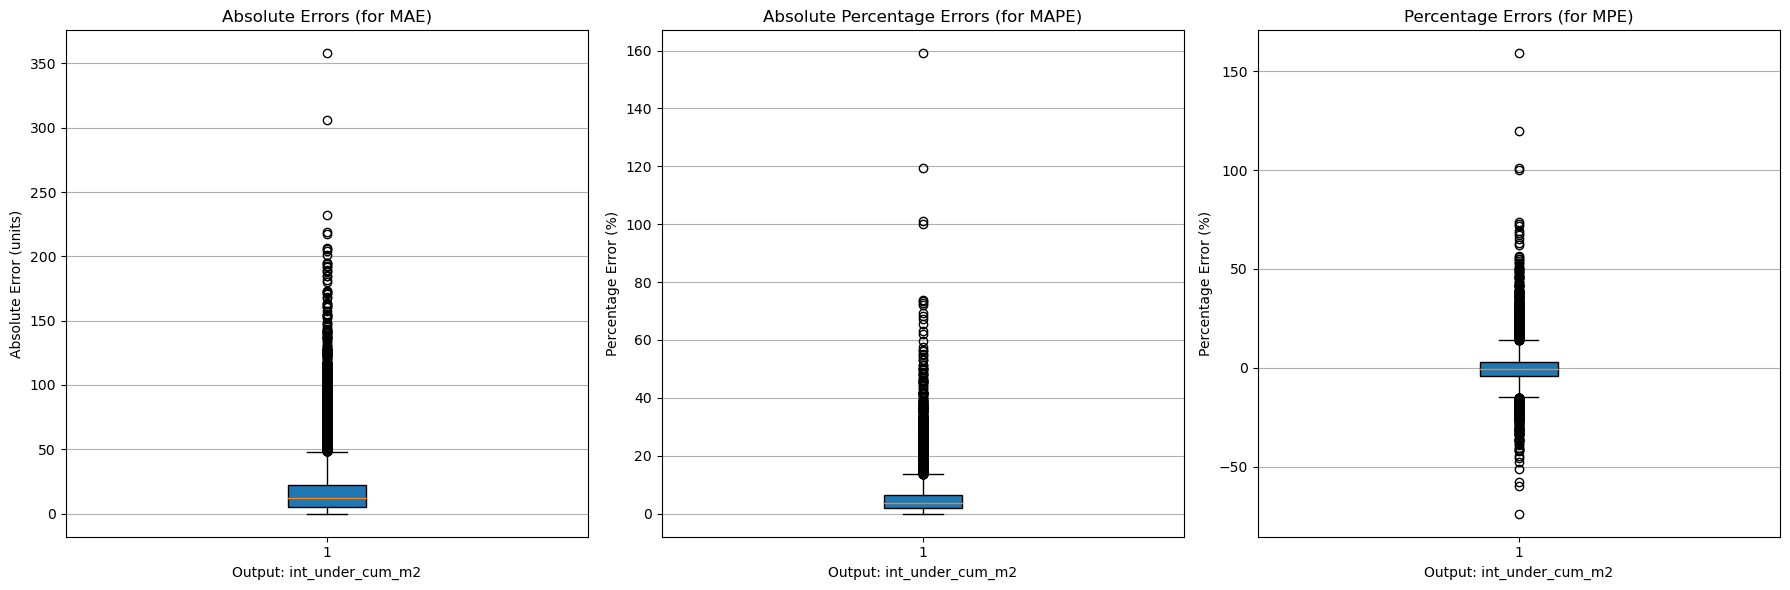

Output: int_over_cum_m2
MAE (valid only): 1.73
MAPE (valid only): 8.46%
MPE (valid only): -0.69%


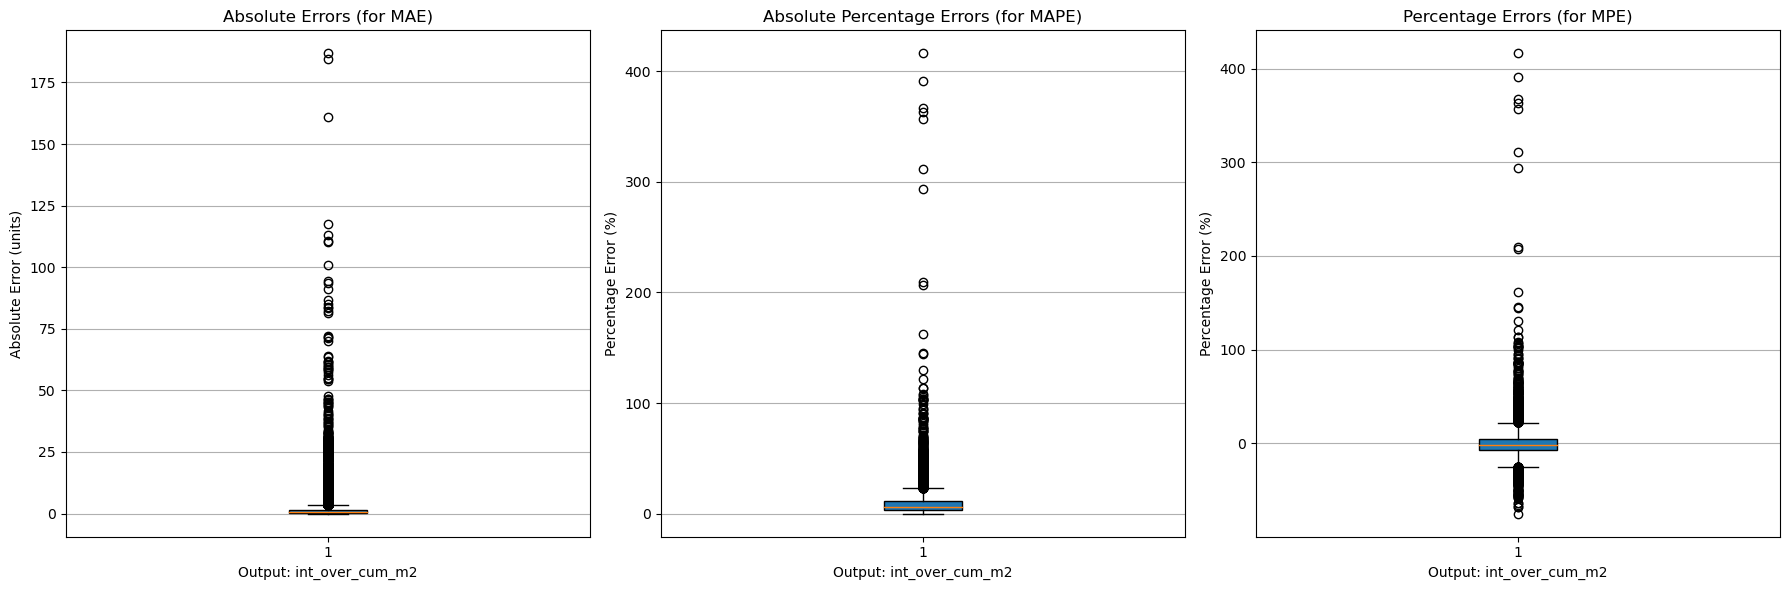

In [ ]:
# Boxplots for final evaluation metrics
output_labels = ['int_under_cum_m2', 'int_over_cum_m2']
all_preds_np = all_preds.detach().cpu().numpy()
all_labels_np = all_labels.detach().cpu().numpy()

mae_per_output = []
mse_per_output = []
mape_per_output = []
mpe_per_output = []

all_preds_denorm = output_scaler.inverse_transform(all_preds_np)
all_labels_denorm = output_scaler.inverse_transform(all_labels_np)

over_idx = label_column.index('int_over_cum_m2')
all_preds_denorm[:, over_idx] = np.expm1(all_preds_denorm[:, over_idx])
all_labels_denorm[:, over_idx] = np.expm1(all_labels_denorm[:, over_idx])
eps=0.1 # So that the metrics are calculated only on the non-zero values

for i in range(all_preds_np.shape[1]):
    y_true = all_labels_denorm[:, i]
    y_pred = all_preds_denorm[:, i]

    valid = np.abs(y_true) > eps
    abs_errors = np.abs(y_pred[valid] - y_true[valid])
    abs_percentage_errors = np.abs((y_pred[valid] - y_true[valid]) / y_true[valid]) * 100
    percentage_errors = ((y_pred[valid] - y_true[valid]) / y_true[valid]) * 100
    mse_errors = ((y_pred[valid] - y_true[valid]) ** 2)

    mae = np.mean(abs_errors)
    mape = np.mean(abs_percentage_errors)
    mpe = np.mean(percentage_errors)
    mse = np.mean(mse_errors)

    mae_per_output.append(mae)
    mse_per_output.append(mse)
    mape_per_output.append(mape)
    mpe_per_output.append(mpe)

    print(f"Output: {output_labels[i]}")
    print(f"MAE (valid only): {mae:.2f}")
    print(f"MAPE (valid only): {mape:.2f}%")
    print(f"MPE (valid only): {mpe:.2f}%")

    if abs_percentage_errors.size > 0:
        plt.figure(figsize=(18, 6))

        plt.subplot(1, 3, 1)
        plt.boxplot(abs_errors, vert=True, patch_artist=True)
        plt.title('Absolute Errors (for MAE)')
        plt.xlabel(f'Output: {output_labels[i]}')
        plt.ylabel('Absolute Error (units)')
        plt.grid(axis='y')

        plt.subplot(1, 3, 2)
        plt.boxplot(abs_percentage_errors, vert=True, patch_artist=True)
        plt.title('Absolute Percentage Errors (for MAPE)')
        plt.xlabel(f'Output: {output_labels[i]}')
        plt.ylabel('Percentage Error (%)')
        plt.grid(axis='y')

        plt.subplot(1, 3, 3)
        plt.boxplot(percentage_errors, vert=True, patch_artist=True)
        plt.title('Percentage Errors (for MPE)')
        plt.xlabel(f'Output: {output_labels[i]}')
        plt.ylabel('Percentage Error (%)')
        plt.grid(axis='y')

        plt.tight_layout()
        plt.show()
    else:
        print('No valid samples for error boxplots at this threshold.')

In [ ]:
# Save the model, input & output scalers and metadata
model_path = "OUT_models/Comfort/pred_comfort_bestunder5848_ReLU.pth"
input_scaler_path = "OUT_models/Comfort/pred_comfort_inputscaler5848_ReLU.pkl"
output_scaler_path = "OUT_models/Comfort/pred_comfort_outputscaler5848_ReLU.pkl"
meta_path = "OUT_models/Comfort/pred_comfort_finalstate_ReLU_meta.json"

model_config = {
    "input_size": model.fc1.in_features,
    "hidden_size1": 128,
    "hidden_size2": 128,
    "hidden_size3": 128,
    "embedding_2d": 2,
    "output_size": 2
}

checkpoint = {
    "model_state_dict": model.state_dict(),
    "model_config": model_config
}
torch.save(checkpoint, model_path)

joblib.dump(input_scaler, input_scaler_path)
joblib.dump(output_scaler, output_scaler_path)

meta = {
    "one_hot_columns": one_hot_columns,
    "numeric_columns": numeric_columns,
    "label_columns": ['int_under_cum_m2', 'int_over_cum_m2'],
    }

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

In [16]:
wandb.finish()